<a href="https://colab.research.google.com/github/Nidhiwa/Canada-Immigration-Analysis/blob/main/01_Data_Exploration_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv"

df_can = pd.read_csv(url)

In [10]:
df_can.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


In [11]:
df_can.shape

(195, 39)

**Clean data**
remove unnecessary columns

1. rename columns for clarity
2. Add a column with total immigration (summing immigration over the years for each country (row))




In [12]:
df_can.columns.tolist()

['Country',
 'Continent',
 'Region',
 'DevName',
 '1980',
 '1981',
 '1982',
 '1983',
 '1984',
 '1985',
 '1986',
 '1987',
 '1988',
 '1989',
 '1990',
 '1991',
 '1992',
 '1993',
 '1994',
 '1995',
 '1996',
 '1997',
 '1998',
 '1999',
 '2000',
 '2001',
 '2002',
 '2003',
 '2004',
 '2005',
 '2006',
 '2007',
 '2008',
 '2009',
 '2010',
 '2011',
 '2012',
 '2013',
 'Total']

In [13]:
df_can.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 39 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Country    195 non-null    object
 1   Continent  195 non-null    object
 2   Region     195 non-null    object
 3   DevName    195 non-null    object
 4   1980       195 non-null    int64 
 5   1981       195 non-null    int64 
 6   1982       195 non-null    int64 
 7   1983       195 non-null    int64 
 8   1984       195 non-null    int64 
 9   1985       195 non-null    int64 
 10  1986       195 non-null    int64 
 11  1987       195 non-null    int64 
 12  1988       195 non-null    int64 
 13  1989       195 non-null    int64 
 14  1990       195 non-null    int64 
 15  1991       195 non-null    int64 
 16  1992       195 non-null    int64 
 17  1993       195 non-null    int64 
 18  1994       195 non-null    int64 
 19  1995       195 non-null    int64 
 20  1996       195 non-null    int64

In [14]:
df_can.isnull().sum()

,0
Country,0
Continent,0
Region,0
DevName,0
1980,0
1981,0
1982,0
1983,0
1984,0
1985,0


How has immigration from India to Canada changed between 1980 and 2013?

In [15]:
india= df_can[df_can['Country']=='India']
india.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
79,India,Asia,Southern Asia,Developing regions,8880,8670,8147,7338,5704,4211,...,36210,33848,28742,28261,29456,34235,27509,30933,33087,691904


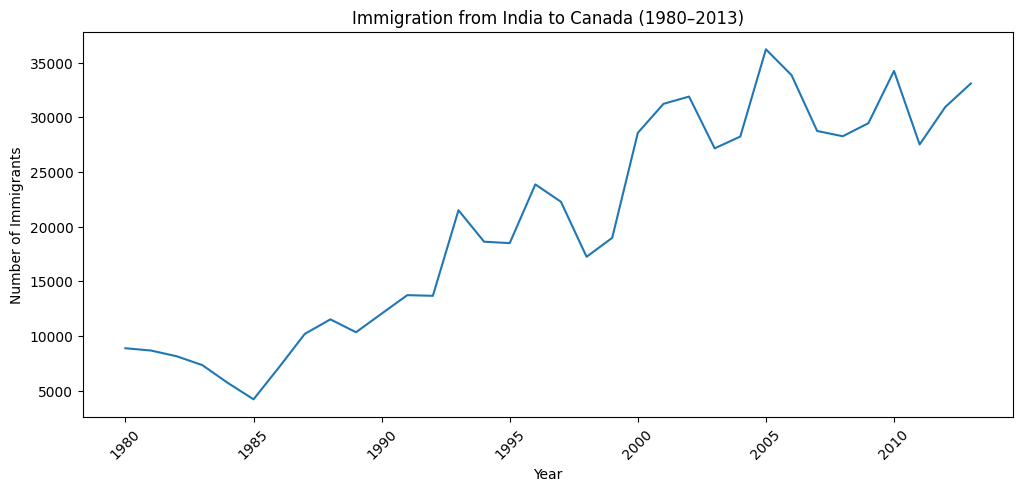

In [16]:

df_can.set_index('Country', inplace=True)


df_can.loc['India', '1980':'2013'].plot(kind='line', figsize=(12, 5))

plt.title('Immigration from India to Canada (1980–2013)')
plt.xlabel('Year')
plt.ylabel('Number of Immigrants')
plt.xticks(rotation=45)
plt.show()

Create a multiple-line chart for these five countries:
- India
- China
- Pakistan
- Philippines
- Sri Lanka
Use the period 1980–2013.

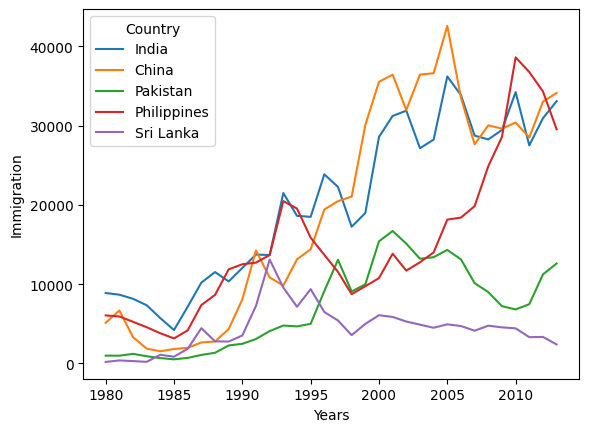

In [17]:
countries=['India','China','Pakistan','Philippines','Sri Lanka']
df_can.loc[countries,'1980':'2013'].transpose().plot(kind='line')
plt.xlabel("Years")
plt.ylabel('Immigration')
plt.show()

Case study
In 2010, Haiti suffered a catastrophic magnitude 7.0 earthquake. The quake caused widespread devastation and loss of life and aout three million people were affected by this natural disaster. As part of Canada's humanitarian effort, the Government of Canada stepped up its effort in accepting refugees from Haiti. We can quickly visualize this effort using a Line plot:

Below is a line plot of immigration from Haiti

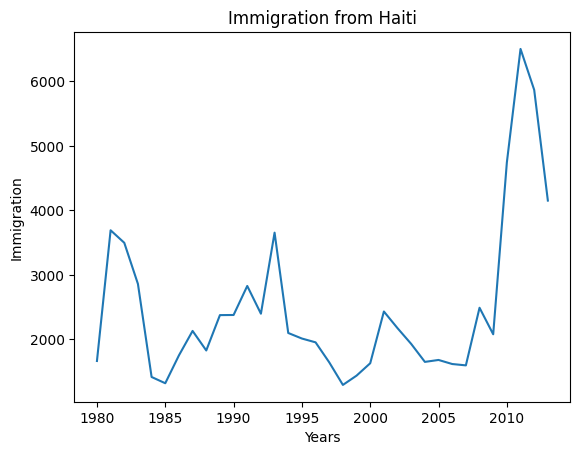

In [18]:
years =list(map(str,range(1980,2014)))

Haiti=df_can.loc['Haiti',years]
Haiti.plot(kind='line')

plt.xlabel('Years')
plt.ylabel('Immigration')
plt.title('Immigration from Haiti')


plt.show()



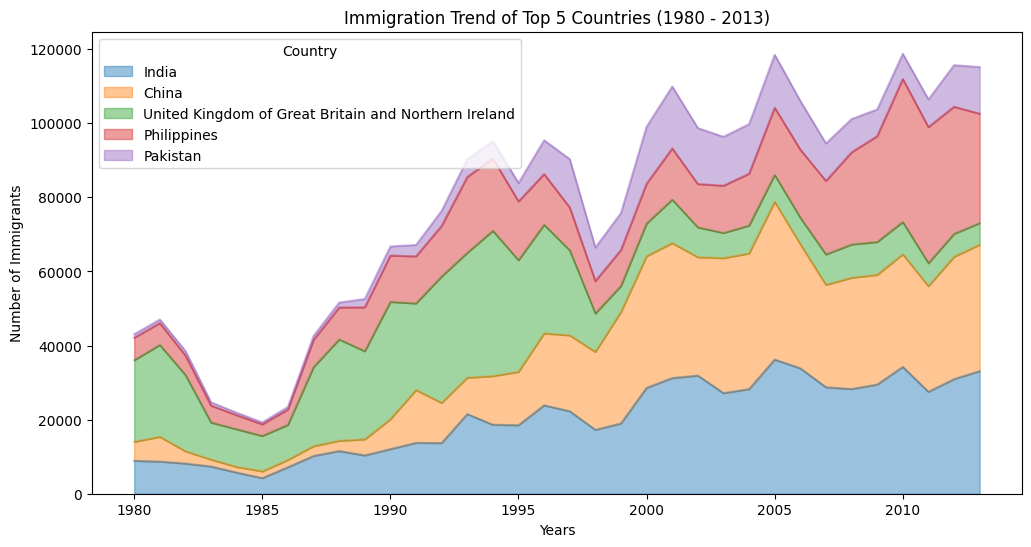

In [19]:
df_top5 = df_can.sort_values(by='Total', ascending=False).head()
df_top5[years].transpose().plot(kind='area', figsize=(12, 6), alpha=0.45)
plt.title('Immigration Trend of Top 5 Countries (1980 - 2013)')
plt.ylabel('Number of Immigrants')
plt.xlabel('Years')
plt.show()

Create a horizontal bar chart showing the total immigration of the top 5 countries.

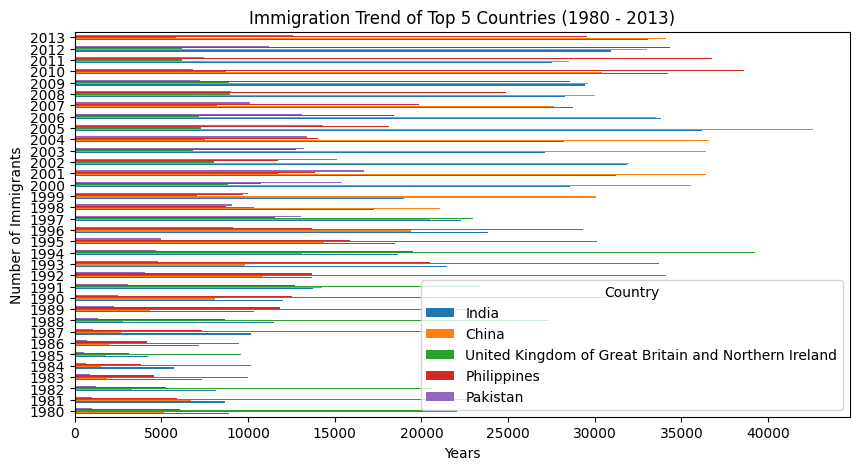

In [20]:
df_top5[years].transpose().plot(

    kind='barh',
    figsize=(10, 5)
)

plt.title('Immigration Trend of Top 5 Countries (1980 - 2013)')
plt.ylabel('Number of Immigrants')
plt.xlabel('Years')
plt.show()

In [21]:
count, bin_edges = np.histogram(df_can['2013'])
print(count)
print(bin_edges)

[178  11   1   2   0   0   0   0   1   2]
[    0.   3412.9  6825.8 10238.7 13651.6 17064.5 20477.4 23890.3 27303.2
 30716.1 34129. ]


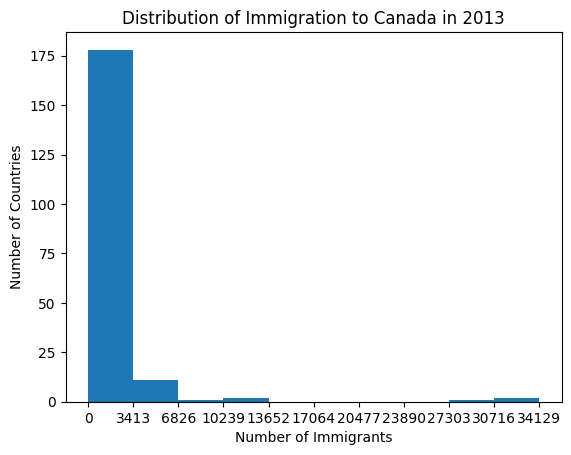

In [22]:
df_can['2013'].plot(kind="hist",xticks=bin_edges)
plt.title('Distribution of Immigration to Canada in 2013')
plt.xlabel('Number of Immigrants')
plt.ylabel('Number of Countries')
plt.show()

Compare immigration distributions across two years(1980, 2013)

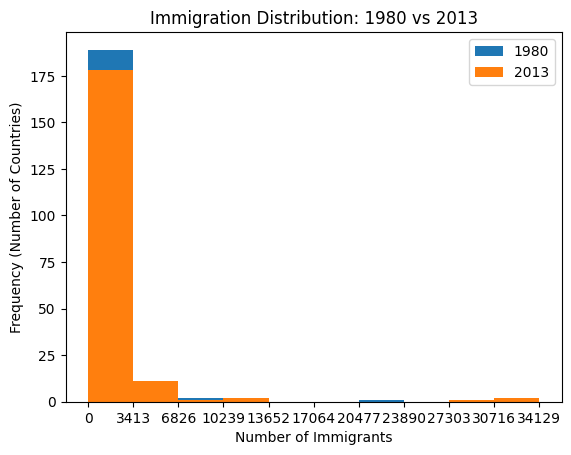

In [24]:
df_can[['1980','2013']].plot(kind="hist", xticks=bin_edges)
plt.title('Immigration Distribution: 1980 vs 2013')
plt.xlabel("Number of Immigrants")
plt.ylabel("Frequency (Number of Countries)")
plt.show()

Histogram distribution of India, China and Pakistan for year 1980 to 2013

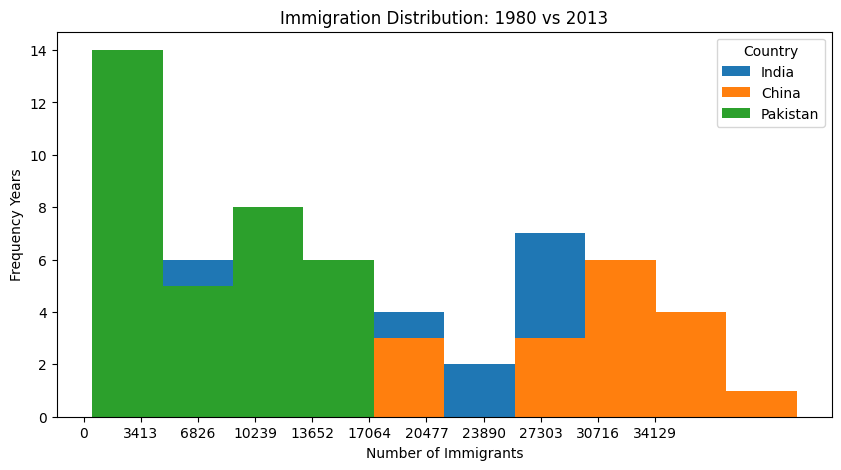

In [25]:
years =list(map(str,range(1980,2013)))
df_con = df_can.loc[["India","China","Pakistan"],years]
df_con.transpose().plot(kind="hist",xticks=bin_edges, figsize=(10,5))

plt.title('Immigration Distribution: 1980 vs 2013')
plt.xlabel('Number of Immigrants')
plt.ylabel('Frequency Years')
plt.show()

Proportion of immigrants grouped by continents for the entier time period from 1980 to 2013

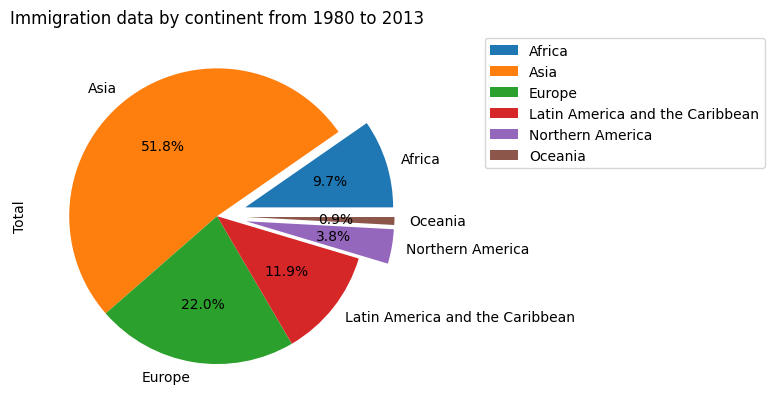

In [26]:
df_cont= df_can.groupby("Continent")['Total'].sum()
df_cont.plot(kind="pie", autopct='%1.1f%%', explode=(0.2, 0, 0, 0, 0.2, 0.2))
plt.title("Immigration data by continent from 1980 to 2013")
plt.legend(df_cont.index,loc= "upper right",bbox_to_anchor=(2, 1))
plt.show()

In [27]:
df_can[years].describe()

,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,508.394872,566.989744,534.723077,387.435897,376.497436,358.861538,441.271795,691.133333,714.389744,843.241026,...,1114.343590,1190.169231,1320.292308,1266.958974,1191.820513,1246.394872,1275.733333,1420.287179,1262.533333,1313.958974
std,1949.588546,2152.643752,1866.997511,1204.333597,1198.246371,1079.309600,1225.576630,2109.205607,2443.606788,2555.048874,...,3623.509519,3710.505369,4425.957828,3926.717747,3443.542409,3694.573544,3829.630424,4462.946328,4030.084313,4247.555161
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.500000,1.000000,1.000000,...,21.500000,19.000000,28.500000,25.000000,31.000000,31.000000,36.000000,40.500000,37.500000,42.500000
50%,13.000000,10.000000,11.000000,12.000000,13.000000,17.000000,18.000000,26.000000,34.000000,44.000000,...,161.000000,191.000000,210.000000,218.000000,198.000000,205.000000,214.000000,211.000000,179.000000,233.000000
75%,251.500000,295.500000,275.000000,173.000000,181.000000,197.000000,254.000000,434.000000,409.000000,508.500000,...,673.500000,756.500000,832.000000,842.000000,899.000000,934.500000,888.000000,932.000000,772.000000,783.000000
max,22045.000000,24796.000000,20620.000000,10015.000000,10170.000000,9564.000000,9470.000000,21337.000000,27359.000000,23795.000000,...,36439.000000,36619.000000,42584.000000,33848.000000,28742.000000,30037.000000,29622.000000,38617.000000,36765.000000,34315.000000


Box plot of India and China

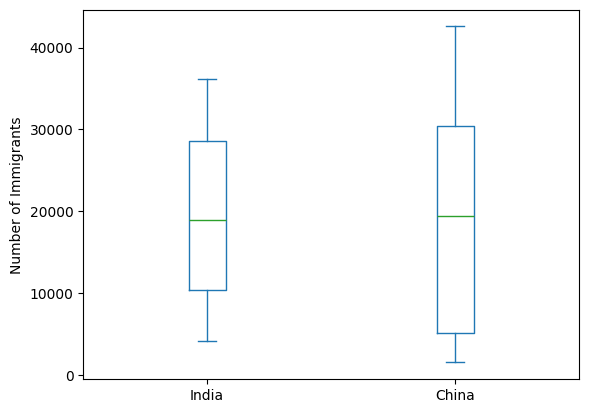

In [28]:

df_ic=df_can.loc[['India','China'],years]
df_ic.transpose().plot(kind="box")
plt.ylabel('Number of Immigrants')
plt.show()

Create a box plot for the top five countries

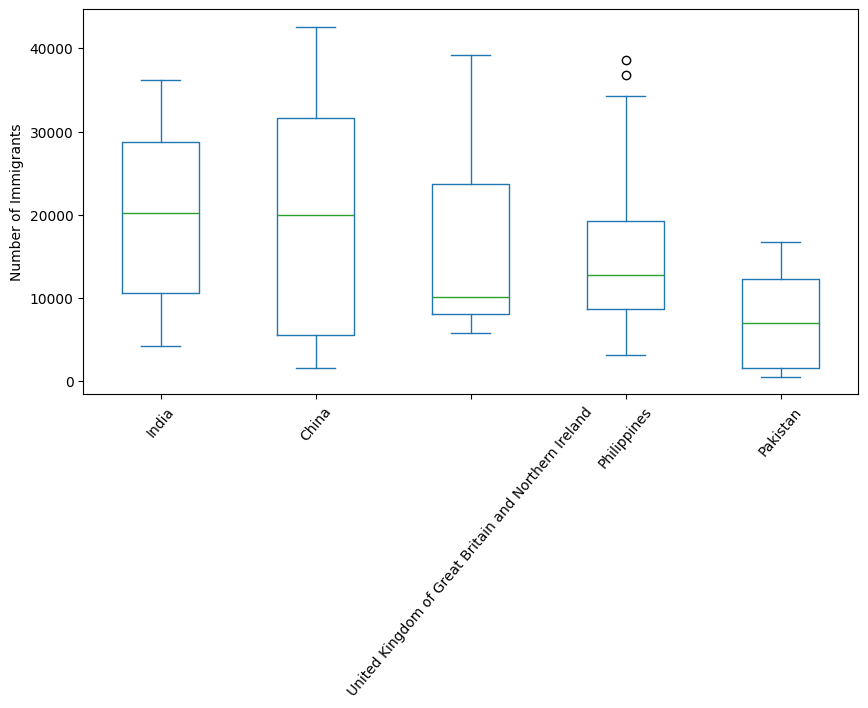

In [43]:
df_top5 = df_can.sort_values(by='Total', ascending=False).head()
years = list(map(str,range(1980,2014)))


df_top5[years].transpose().plot(kind="box",figsize=(10,5))
plt.xticks(rotation=50)
plt.ylabel('Number of Immigrants')
plt.show()

which years had unusually high or low immigration from India.

In [44]:
Q1 = df_can.loc['India', years].quantile(0.25)

Q3 = df_can.loc['India', years].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)
print('Lower boundary:', lower)
print('Upper boundary:', upper)

Q1: 10637.75
Q3: 28699.5
IQR: 18061.75
Lower boundary: -16454.875
Upper boundary: 55792.125


25% of the years had immigration values below 10,637.75.



75% of the years had immigration values below 28,699.50.



The middle 50% of immigration values are spread across 18,061.75.

Outliers

In [47]:
india = df_can.loc['India', years]

outliers = india[
    (india < lower) | (india > upper)
]

print(outliers)

Series([], Name: India, dtype: object)


India vs China scatter plot

Text(0, 0.5, 'China Immigration')

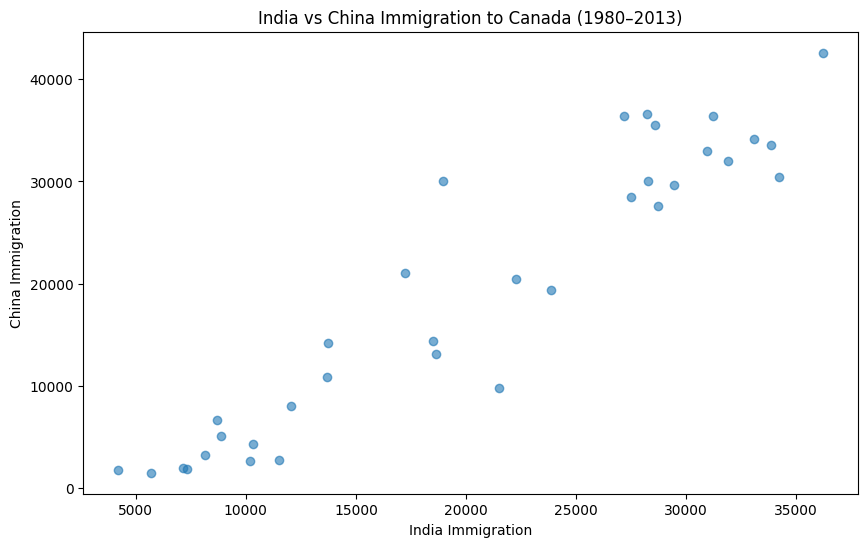

In [53]:
df_scatter = df_can.loc[['India', 'China'], '1980':'2013']


df_scatter = df_scatter.transpose()


plt.figure(figsize=(10, 6))

plt.scatter(
    df_scatter['India'],
    df_scatter['China'],
    alpha=0.6,
    label='India vs China'
)

plt.title('India vs China Immigration to Canada (1980–2013)')
plt.xlabel('India Immigration')
plt.ylabel('China Immigration')

In [55]:
corr=df_scatter['India'].corr(df_scatter['China'])
print(corr)

0.94316189731992


Correlation Analysis: India vs China (1980–2013)

The Pearson correlation coefficient between immigration from India and China was 0.9432, indicating a very strong positive linear relationship. This suggests that immigration trends from both countries generally moved together during the study period.

In [60]:
corr1=df_can.loc[['India', 'China', 'Pakistan'], '1980':'2013'].transpose().corr()

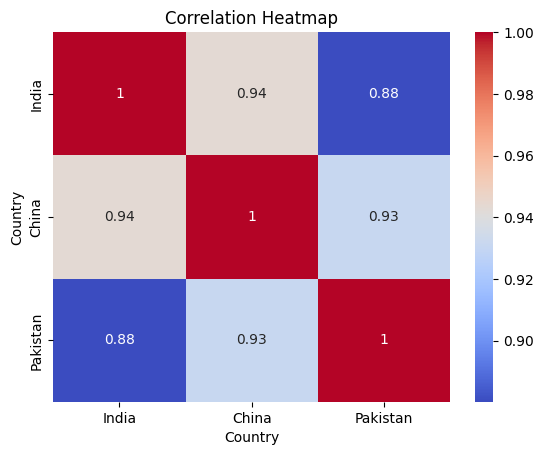

In [61]:
sns.heatmap(corr1,cmap="coolwarm",annot=True)
plt.title("Correlation Heatmap")
plt.show()

Key Finding:

The correlation analysis revealed very strong positive relationships among immigration trends from India, China, and Pakistan between 1980 and 2013. The strongest relationship was between India and China (0.9432), followed by China and Pakistan (0.9309), and India and Pakistan (0.8803).

These results indicate that immigration patterns across these three countries tended to move together over the study period. However, correlation does not establish causation.

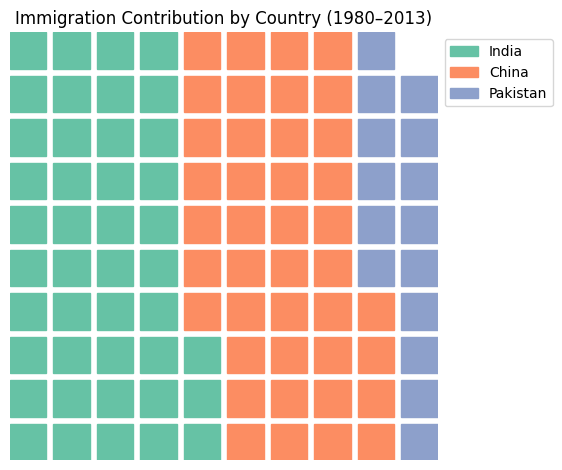

In [63]:
!pip install pywaffle
from pywaffle import Waffle

# Select countries
countries = ['India', 'China', 'Pakistan']

# Calculate total immigration from 1980 to 2013
df_waffle = df_can.loc[countries, '1980':'2013']

totals = df_waffle.sum(axis=1)

# Create Waffle chart
fig = plt.figure(
    FigureClass=Waffle,
    rows=10,
    columns=10,
    values=totals,
    labels=countries,
    legend={'loc': 'upper left', 'bbox_to_anchor': (1, 1)}
)

plt.title('Immigration Contribution by Country (1980–2013)')
plt.show()

Create a Waffle chart to display the proportions of China's and India's contributions to total immigration.

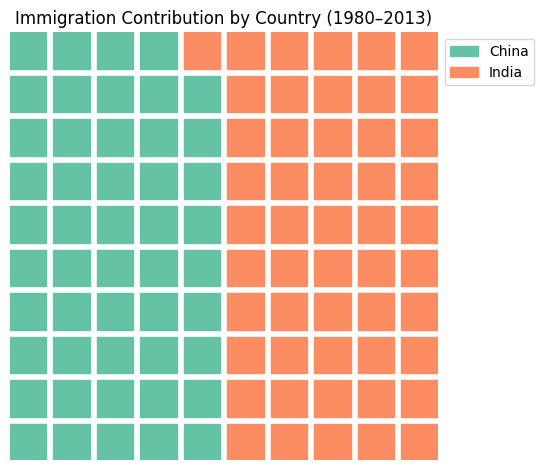

In [80]:
df_ci = df_can.loc[['China', 'India'], :]
Total_imm = df_ci['Total'].sum()
total_p = df_ci['Total'] / Total_imm

values = {
    'China': total_p['China'],
    'India': total_p['India']
}

# Corrected by putting bbox_to_anchor inside the legend dictionary
plt.figure(
    FigureClass=Waffle,
    rows=10,
    columns=10,
    values=values,
    legend={'loc': 'upper left', 'bbox_to_anchor': (1, 1)}
)
plt.title('Immigration Contribution by Country (1980–2013)')
plt.show()